# Chapter 17: The shortest trip

Checks [chapter 17](../../book/17-the-shortest-trip.md). Two models, both exact and small. The first is a
**linear model in its weights**: `output = features @ weights`, trained by plain gradient descent on the squared error.
The second is a stack of polarizer plates, each keeping `cos(turn)` of the light amplitude, as in chapter 12.
Everything is NumPy in float64, seeded. These are measurements, not proofs: the proofs are in `LeastAction.lean`.
The remark in the author's notes about "balanced layers" under a gradient step is not tested here. Run every cell,
top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE

use_style()
SEED = 17


def take_gradient_step(features, labels, learning_rate, weights):
    """One step on the loss 0.5 * sum (features @ weights - labels)^2: it adds a multiple of features^T times the error."""
    error = labels - features @ weights
    return weights + learning_rate * features.T @ error


def measure_travel(weights, start_weights):
    return float(np.linalg.norm(weights - start_weights))


def measure_output_error(features, labels, weights):
    """The vertical error: what the loss sees. It is zero at a fit."""
    return float(np.abs(features @ weights - labels).max())

## Claim 1: the example by hand

One data point, features `(1, 1)`, label 4, start `(1, 0)`, learning rate 0.5. **Predicted:** one step lands on `(2.5, 1.5)`,
a fit, with travel `sqrt(4.5)` = 2.1213; the fits `(4, 0)` and `(0, 4)` are at travel 3 and `sqrt(17)` = 4.1231.
**Counts against the claim:** a landing point off the line `weight_1 + weight_2 = 4`, or any of 100 001 fits spread along
that line being nearer than the landing point.
The control breaks the hypothesis that the move lies along the features: a real descent with the preconditioner
`diag(1, 0)` has every step along `(1, 0)`, reaches the fit `(4, 0)`, and must be further than the nearest one. The two
hand-picked fits `(4, 0)` and `(0, 4)` are printed as by construction: their travel is arithmetic, not a measurement. The output error is printed next to every travel;
at a fit it is zero, so the vertical error cannot tell the fits apart and only the travel can.

In [2]:
EXAMPLE_FEATURES = np.array([[1.0, 1.0]])
EXAMPLE_LABELS = np.array([4.0])
EXAMPLE_START = np.array([1.0, 0.0])
EXAMPLE_RATE = 0.5

landing = take_gradient_step(EXAMPLE_FEATURES, EXAMPLE_LABELS, EXAMPLE_RATE, EXAMPLE_START)
landing_travel = measure_travel(landing, EXAMPLE_START)
landing_error = measure_output_error(EXAMPLE_FEATURES, EXAMPLE_LABELS, landing)
print(f"landing {landing}, travel {landing_travel:.4f}, vertical error {landing_error:.1e}")

other_fits = {"(4, 0)": np.array([4.0, 0.0]), "(0, 4)": np.array([0.0, 4.0])}
for name, fit in other_fits.items():
    print(f"fit {name}: travel {measure_travel(fit, EXAMPLE_START):.4f}, "
          f"vertical error {measure_output_error(EXAMPLE_FEATURES, EXAMPLE_LABELS, fit):.1e}")

line_positions = np.linspace(-50.0, 50.0, 100001)
line_fits = np.stack([line_positions, 4.0 - line_positions], axis=1)
line_travels = np.linalg.norm(line_fits - EXAMPLE_START, axis=1)
line_errors = np.abs(line_fits @ EXAMPLE_FEATURES[0] - EXAMPLE_LABELS[0])

report("one step lands on (2.5, 1.5) with travel sqrt(4.5)",
       np.allclose(landing, [2.5, 1.5]) and abs(landing_travel - np.sqrt(4.5)) < 1e-12, f"travel {landing_travel:.4f}")
report("the landing point is a fit", landing_error < 1e-12, f"vertical error {landing_error:.1e}")
print("[by construction, cannot fail] the two hand-picked fits are at travel 3 and sqrt(17): "
      f"{measure_travel(other_fits['(4, 0)'], EXAMPLE_START):.4f} and {measure_travel(other_fits['(0, 4)'], EXAMPLE_START):.4f}")
report("no fit among 100 001 along the line is nearer than the landing point",
       line_travels.min() >= landing_travel - 1e-9 and line_errors.max() < 1e-9,
       f"nearest on the line {line_travels.min():.6f}, vertical errors up to {line_errors.max():.1e}")

# Control: a real descent whose steps are not along the features (1, 1): the preconditioner diag(1, 0) turns every
# step into a move along (1, 0). It is run, not placed by hand.
control_preconditioner = np.diag([1.0, 0.0])
off_features_fit = EXAMPLE_START.copy()
for _ in range(60):
    off_features_fit = off_features_fit + 0.5 * control_preconditioner @ EXAMPLE_FEATURES.T @ (EXAMPLE_LABELS - EXAMPLE_FEATURES @ off_features_fit)
control_travel = measure_travel(off_features_fit, EXAMPLE_START)
control_error = measure_output_error(EXAMPLE_FEATURES, EXAMPLE_LABELS, off_features_fit)
report("control: a descent whose steps leave the features reaches a fit but travels further",
       control_error < 1e-9 and control_travel > landing_travel + 0.5,
       f"travel {control_travel:.4f} against {landing_travel:.4f}, vertical error {control_error:.1e}, excess {control_travel - landing_travel:.4f}")

landing [2.5 1.5], travel 2.1213, vertical error 0.0e+00
fit (4, 0): travel 3.0000, vertical error 0.0e+00
fit (0, 4): travel 4.1231, vertical error 0.0e+00
[PASS] one step lands on (2.5, 1.5) with travel sqrt(4.5)  (travel 2.1213)
[PASS] the landing point is a fit  (vertical error 0.0e+00)
[by construction, cannot fail] the two hand-picked fits are at travel 3 and sqrt(17): 3.0000 and 4.1231
[PASS] no fit among 100 001 along the line is nearer than the landing point  (nearest on the line 2.121320, vertical errors up to 3.6e-15)
[PASS] control: a descent whose steps leave the features reaches a fit but travels further  (travel 3.0000 against 2.1213, vertical error 0.0e+00, excess 0.8787)


True

## Figure 1: the line of fits

**Measured.** The line of fits, the start, the point gradient descent lands on, and the two other fits with their
travel. The move to the landing point is at right angles to the line, which is why it is shortest.

wrote book/figures/17-line-of-fits.png


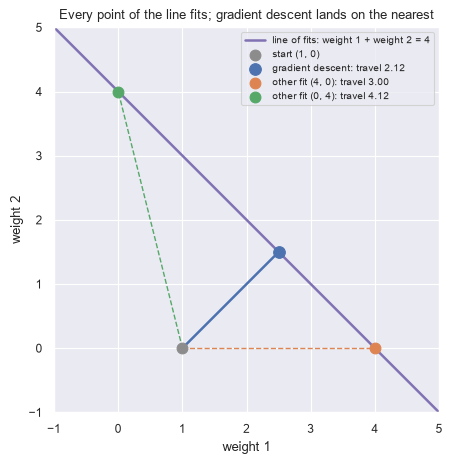

In [3]:
use_style()
figure, axis = plt.subplots(figsize=(5.5, 5.0))
visible = (line_positions > -1.5) & (line_positions < 5.5)
axis.plot(line_fits[visible, 0], line_fits[visible, 1], color=MODEL, linewidth=1.8, label="line of fits: weight 1 + weight 2 = 4")
axis.scatter(*EXAMPLE_START, color=BEFORE, s=60, zorder=4, label="start (1, 0)")
axis.scatter(*landing, color=NEAREST, s=70, zorder=4, label=f"gradient descent: travel {landing_travel:.2f}")
for (name, fit), colour in zip(other_fits.items(), (VERTICAL, BOUND)):
    travel = measure_travel(fit, EXAMPLE_START)
    axis.scatter(*fit, color=colour, s=60, zorder=4, label=f"other fit {name}: travel {travel:.2f}")
    axis.plot([EXAMPLE_START[0], fit[0]], [EXAMPLE_START[1], fit[1]], color=colour, linestyle="--", linewidth=1.0)
axis.plot([EXAMPLE_START[0], landing[0]], [EXAMPLE_START[1], landing[1]], color=NEAREST, linewidth=1.8)
axis.set_aspect("equal")
axis.set_xlim(-1.0, 5.0)
axis.set_ylim(-1.0, 5.0)
axis.set_xlabel("weight 1")
axis.set_ylabel("weight 2")
axis.set_title("Every point of the line fits; gradient descent lands on the nearest")
axis.legend(loc="upper right", fontsize=7)
save_figure(figure, "17-line-of-fits")
plt.show()

## Claim 2: the nearest fit, in random linear models

The Lean theorem is for any linear model. Take 40 random models with 3 to 8 data points and 12 to 30 weights (so there are
many fits), a random start and a learning rate under `1 / largest_eigenvalue` of `features @ features^T`. Run gradient descent
until the output error is below `1e-13`, then compare its travel with the travel of 2000 other fits per model: the start plus the
minimum-norm move, plus a random move in the null space of the features. **Predicted:** the gradient descent fit equals the
minimum-norm one, and no other fit is nearer. The theorem covers landing exactly; the stopping rule `1e-13` leaves a tiny
slack, so the allowed shortfall is `1e-9`, and the smallest margin by which another fit is nearer is reported.
**Counts against the claim:** any other fit nearer by more than `1e-9`. The control runs the descent with a
preconditioner `diag(1, 5, 1, 5, ...)`, so the move leaves the span of the features: it also reaches a fit, which must be
further than the minimum-norm one in most models.

In [4]:
generator = np.random.default_rng(SEED)
ERROR_STOP = 1e-13
nearest_margin = np.inf      # travel of another fit minus travel of gradient descent: must be >= -1e-9
descent_gap = 0.0            # gradient descent travel minus minimum-norm travel
worst_output_error = 0.0
control_excesses = []
for _ in range(40):
    data_count = int(generator.integers(3, 9))
    weight_count = int(generator.integers(12, 31))
    features = generator.standard_normal((data_count, weight_count))
    labels = generator.standard_normal(data_count) * 2.0
    start = generator.standard_normal(weight_count)
    learning_rate = 0.9 / np.linalg.eigvalsh(features @ features.T).max()

    weights = start.copy()
    for step in range(200000):
        if measure_output_error(features, labels, weights) < ERROR_STOP:
            break
        weights = take_gradient_step(features, labels, learning_rate, weights)
    travel = measure_travel(weights, start)
    worst_output_error = max(worst_output_error, measure_output_error(features, labels, weights))

    minimum_move = np.linalg.pinv(features) @ (labels - features @ start)
    descent_gap = max(descent_gap, abs(travel - np.linalg.norm(minimum_move)))
    null_basis = np.linalg.svd(features)[2][data_count:].T
    for _ in range(2000):
        scale = generator.choice([0.01, 0.5, 3.0])
        other_move = minimum_move + null_basis @ (generator.standard_normal(null_basis.shape[1]) * scale)
        assert measure_output_error(features, labels, start + other_move) < 1e-9
        nearest_margin = min(nearest_margin, np.linalg.norm(other_move) - travel)

    # control: preconditioned steps, so the move leaves the span of the features
    preconditioner = np.diag(np.where(np.arange(weight_count) % 2 == 0, 1.0, 5.0))
    scaled_rate = 0.9 / np.linalg.eigvalsh(features @ preconditioner @ features.T).max()
    control_weights = start.copy()
    for step in range(200000):
        if measure_output_error(features, labels, control_weights) < ERROR_STOP:
            break
        control_weights = control_weights + scaled_rate * preconditioner @ features.T @ (labels - features @ control_weights)
    control_excesses.append(measure_travel(control_weights, start) - np.linalg.norm(minimum_move))

control_share = float(np.mean(np.array(control_excesses) > 1e-6))
report("gradient descent reaches the minimum-norm fit in 40 random models", descent_gap < 1e-6 and worst_output_error < 1e-12,
       f"largest travel gap {descent_gap:.1e}, largest vertical error {worst_output_error:.1e}")
report("no other fit of 80 000 is nearer than the gradient descent fit", nearest_margin >= -1e-9,
       f"smallest margin {nearest_margin:.2e}")
report("control: the preconditioned descent reaches a fit that is further in most models",
       control_share > 0.9, f"further in {control_share:.0%} of models, largest excess {max(control_excesses):.3f}")

[PASS] gradient descent reaches the minimum-norm fit in 40 random models  (largest travel gap 1.0e-13, largest vertical error 1.0e-13)
[PASS] no other fit of 80 000 is nearer than the gradient descent fit  (smallest margin 9.22e-06)
[PASS] control: the preconditioned descent reaches a fit that is further in most models  (further in 100% of models, largest excess 1.108)


True

## Claim 3: two plates, the average turn keeps at least as much light

Plates turn the light by `first_turn` and `second_turn`; the light amplitude kept is `cos(first_turn) * cos(second_turn)`,
against `cos(average_turn) ** 2` for two turns of the average. **Predicted:** over 200 000 random pairs of turns in
`[0, pi/2]`, no pair beats its average. The cosine check is **from the formula**. The chapter's example and 2000 more pairs are also run through 2 by 2 projection matrices, which is the measured part. **Counts against the claim:** any pair that keeps more by more than `1e-15`.

In [5]:
def make_plate(plate_angle):
    axis = np.array([np.cos(plate_angle), np.sin(plate_angle)])
    return np.outer(axis, axis)


def keep_light_through_turns(turns):
    """Light enters along the first plate's axis; each next plate is turned by its turn from the one before."""
    return float(np.prod(np.cos(turns)))


generator = np.random.default_rng(SEED + 1)
first_turns = generator.uniform(0.0, np.pi / 2, 200000)
second_turns = generator.uniform(0.0, np.pi / 2, 200000)
kept_by_two = np.cos(first_turns) * np.cos(second_turns)
kept_by_average = np.cos((first_turns + second_turns) / 2) ** 2
largest_win = float((kept_by_two - kept_by_average).max())

# Matrix reading of the example. Light of length 1 lies along angle 0. Plate k has its axis at the running total of the
# turns, so a turn is the angle between neighbouring plates. The kept length is read off the product of the 2 by 2 matrices.
def pass_through_turns(turns, light):
    for plate_angle in np.cumsum(turns):
        light = make_plate(plate_angle) @ light
    return float(np.linalg.norm(light))


light_in = np.array([1.0, 0.0])
sixty = np.radians(60)
matrix_kept = pass_through_turns([sixty, 0.0], light_in)
matrix_even = pass_through_turns([sixty / 2, sixty / 2], light_in)
print(f"matrices: turns 60 and 0 keep {matrix_kept:.4f}; turns 30 and 30 keep {matrix_even:.4f}")
report("[from the formula] two plates: no pair of turns keeps more than two turns of the average", largest_win <= 1e-15,
       f"largest amount by which a pair beat its average {largest_win:.1e}")
report("[from the 2 by 2 matrices] the example: 60 and 0 degrees keep 0.5, two turns of 30 degrees keep 0.75",
       abs(matrix_kept - 0.5) < 1e-12 and abs(matrix_even - 0.75) < 1e-12)
matrix_pair_gap = -np.inf
for _ in range(2000):
    first_turn, second_turn = generator.uniform(0.0, np.pi / 2, 2)
    matrix_pair_gap = max(matrix_pair_gap, pass_through_turns([first_turn, second_turn], light_in)
                          - pass_through_turns([(first_turn + second_turn) / 2] * 2, light_in))
report("[from the 2 by 2 matrices] 2000 random pairs: none keeps more than two turns of its average", matrix_pair_gap <= 1e-12,
       f"largest amount by which a pair beat its average {matrix_pair_gap:.1e}")

matrices: turns 60 and 0 keep 0.5000; turns 30 and 30 keep 0.7500
[PASS] [from the formula] two plates: no pair of turns keeps more than two turns of the average  (largest amount by which a pair beat its average -1.7e-14)
[PASS] [from the 2 by 2 matrices] the example: 60 and 0 degrees keep 0.5, two turns of 30 degrees keep 0.75
[PASS] [from the 2 by 2 matrices] 2000 random pairs: none keeps more than two turns of its average  (largest amount by which a pair beat its average -2.1e-08)


True

## Claim 4: N plates with a fixed total turn, equal turns keep the most light

The chapter argues this by repeating the two-plate comparison, and marks the last step **open**. The big sweep below computes the kept light **from the formula** (the product of cosines); a smaller run
through the 2 by 2 matrices is the measured part. The prediction before
any run: for every `N` in 2, 3, 10 and 100 and every total turn of at most a quarter turn (`pi/2`, `pi/4` and 0.3), the equal
split `cos(total / N) ** N` keeps at least as much as any split into `N` turns, each at least 0, with the same total.
Four kinds of split are drawn, 20 000 of each for every `N` and total: uniform on the simplex (Dirichlet 1), lopsided
(Dirichlet 0.1), one big turn of 90% of the total with the rest even, and the equal split plus small noise, which is where a
counterexample would hide. **Counts against the claim:** one split that keeps more than the equal split by more than `1e-15`.
The largest amount by which any random split beat the equal split is reported (negative means none did). The
equal-split amplitude `cos(pi / (2 N)) ** N` (the Lean `kept_fraction`) is also compared with the bound `1 - pi^2/(8 N)` of
`quarter_turn_arrives`. This is evidence for the cases drawn, not a proof.
The control breaks the hypothesis that the total is at most a quarter turn: with total `2 pi` and `N = 3`, a split whose
cosines have cancelling signs keeps far more than the equal one.

In [6]:
generator = np.random.default_rng(SEED + 2)
SPLIT_COUNT = 20000
PLATE_COUNTS = (2, 3, 10, 100)
TOTAL_TURNS = (np.pi / 2, np.pi / 4, 0.3)
SPLIT_KINDS = ("uniform", "lopsided", "one big turn", "near equal")


def draw_splits(plate_count, total_turn, kind):
    if kind == "uniform":
        shares = generator.dirichlet(np.ones(plate_count), SPLIT_COUNT)
    elif kind == "lopsided":
        shares = generator.dirichlet(np.full(plate_count, 0.1), SPLIT_COUNT)
    elif kind == "one big turn":
        shares = np.full((SPLIT_COUNT, plate_count), 0.1 / (plate_count - 1))
        shares[np.arange(SPLIT_COUNT), generator.integers(0, plate_count, SPLIT_COUNT)] = 0.9
    else:
        noise_scale = generator.choice([1e-3, 1e-2, 1e-1], (SPLIT_COUNT, 1))
        noise = generator.standard_normal((SPLIT_COUNT, plate_count)) * noise_scale / plate_count
        shares = np.clip(1.0 / plate_count + noise, 0.0, None)
        shares /= shares.sum(axis=1, keepdims=True)
    return shares * total_turn


rows = []
for plate_count in PLATE_COUNTS:
    for total_turn in TOTAL_TURNS:
        equal_kept = float(np.cos(total_turn / plate_count) ** plate_count)
        for kind in SPLIT_KINDS:
            splits = draw_splits(plate_count, total_turn, kind)
            assert np.allclose(splits.sum(axis=1), total_turn) and (splits >= 0).all()
            kept = np.exp(np.log(np.cos(splits)).sum(axis=1))
            rows.append((plate_count, total_turn, kind, equal_kept, float(kept.max()), float(kept.max()) - equal_kept))

# The model run: light through N projection matrices, 2000 uniform splits per N, against the equal split.
MATRIX_SPLITS = 2000
matrix_beat = -np.inf
matrix_formula_gap = 0.0
for plate_count in PLATE_COUNTS:
    splits = generator.dirichlet(np.ones(plate_count), MATRIX_SPLITS) * (np.pi / 2)
    axes = np.cumsum(splits, axis=1)
    light = np.tile([1.0, 0.0], (MATRIX_SPLITS, 1))
    for plate_index in range(plate_count):
        axis_vectors = np.stack([np.cos(axes[:, plate_index]), np.sin(axes[:, plate_index])], axis=1)
        light = axis_vectors * (light * axis_vectors).sum(axis=1, keepdims=True)       # the projection matrix applied
    matrix_kept = np.linalg.norm(light, axis=1)
    equal_light = np.array([1.0, 0.0])
    for equal_axis in np.cumsum(np.full(plate_count, np.pi / 2 / plate_count)):
        equal_light = make_plate(equal_axis) @ equal_light
    matrix_beat = max(matrix_beat, float(matrix_kept.max() - np.linalg.norm(equal_light)))
    matrix_formula_gap = max(matrix_formula_gap, float(np.abs(matrix_kept - np.cos(splits).prod(axis=1)).max()))
    print(f"N = {plate_count}: matrix run, best of {MATRIX_SPLITS} random splits {matrix_kept.max():.6f}, equal split {np.linalg.norm(equal_light):.6f}")
report("[from the 2 by 2 matrices] no random split beat the equal split, N = 2, 3, 10, 100", matrix_beat <= 1e-12,
       f"largest amount by which a split beat the equal one {matrix_beat:.1e}")
report("[from the 2 by 2 matrices] the matrix run agrees with the product of cosines", matrix_formula_gap < 1e-12,
       f"largest gap {matrix_formula_gap:.1e}")

table = pd.DataFrame(rows, columns=["plates", "total_turn", "kind", "equal_kept", "best_random_kept", "random_minus_equal"])
quarter = table[np.isclose(table.total_turn, np.pi / 2)]
print(quarter.to_string(index=False, float_format=lambda value: f"{value:.3e}" if abs(value) < 1e-3 else f"{value:.6f}"))
largest_beat = float(table.random_minus_equal.max())
print(f"split draws: {len(rows) * SPLIT_COUNT}")
report("[from the formula] no random split beat the equal split", largest_beat <= 1e-15,
       f"largest amount by which any random split beat the equal split {largest_beat:.1e}")
print(f"closest approach to the equal split, by kind (best random minus equal, largest over N and total):")
print(table.groupby("kind").random_minus_equal.max().to_string(float_format=lambda value: f"{value:.2e}"))

bound_margins = []
for plate_count in PLATE_COUNTS:
    equal_amplitude = float(np.cos(np.pi / 2 / plate_count) ** plate_count)
    bound = 1.0 - np.pi ** 2 / (8 * plate_count)
    bound_margins.append(equal_amplitude - bound)
    print(f"N = {plate_count}: equal-split amplitude {equal_amplitude:.6f}, bound {bound:.6f}")
report("[from the formula] the equal split's amplitude is at least 1 - pi^2/(8 N) for N = 2, 3, 10, 100", min(bound_margins) >= 0.0,
       f"smallest margin {min(bound_margins):.2e}")

control_total = 2.0 * np.pi
control_splits = generator.dirichlet(np.ones(3), SPLIT_COUNT) * control_total
control_kept = np.cos(control_splits).prod(axis=1)
control_equal = float(np.cos(control_total / 3) ** 3)
control_beat = float(control_kept.max() - control_equal)
report("[from the formula] control: with a total turn of 2 pi the equal split is beaten", control_beat > 0.5,
       f"largest amount by which a random split beat the equal one {control_beat:.3f} (equal keeps {control_equal:.3f})")

N = 2: matrix run, best of 2000 random splits 0.500000, equal split 0.500000
N = 3: matrix run, best of 2000 random splits 0.649332, equal split 0.649519
N = 10: matrix run, best of 2000 random splits 0.869165, equal split 0.883485
N = 100: matrix run, best of 2000 random splits 0.980979, equal split 0.987738
[PASS] [from the 2 by 2 matrices] no random split beat the equal split, N = 2, 3, 10, 100  (largest amount by which a split beat the equal one -1.8e-08)
[PASS] [from the 2 by 2 matrices] the matrix run agrees with the product of cosines  (largest gap 3.9e-15)
 plates  total_turn         kind  equal_kept  best_random_kept  random_minus_equal
      2    1.570796      uniform    0.500000          0.500000          -1.393e-09
      2    1.570796     lopsided    0.500000          0.500000          -1.633e-08
      2    1.570796 one big turn    0.500000          0.154508           -0.345492
      2    1.570796   near equal    0.500000          0.500000          -4.996e-16
      3    1.5

True

## Figure 2: light kept through N plates

**From the formula** (product of cosines, checked against the matrices above). The light amplitude kept through `N` plates that turn by a quarter turn in total, for the equal split and for
random unequal splits of the same total (40 uniform-on-the-simplex splits per `N`). The line is the equal split.

wrote book/figures/17-n-plates.png


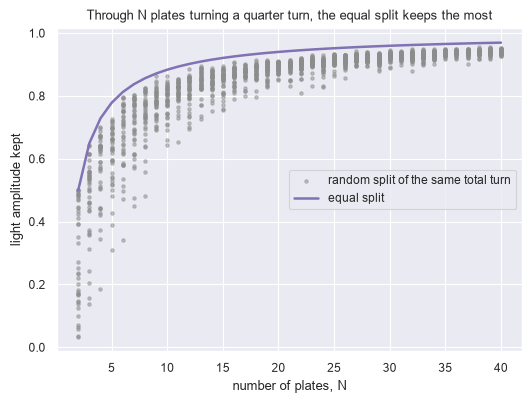

[PASS] [from the formula] in the figure, no dot is above the equal-split line  (largest dot minus line -4.3e-05)


True

In [7]:
use_style()
generator = np.random.default_rng(SEED + 3)
figure, axis = plt.subplots(figsize=(6.0, 4.2))
plate_counts = np.arange(2, 41)
equal_curve = np.cos(np.pi / 2 / plate_counts) ** plate_counts
dot_counts, dot_kept = [], []
for plate_count in plate_counts:
    shares = generator.dirichlet(np.ones(plate_count), 40)
    dot_counts.extend([plate_count] * 40)
    dot_kept.extend(np.cos(shares * np.pi / 2).prod(axis=1))
axis.scatter(dot_counts, dot_kept, s=6, color=BEFORE, alpha=0.5, label="random split of the same total turn")
axis.plot(plate_counts, equal_curve, color=MODEL, linewidth=1.8, label="equal split")
axis.set_xlabel("number of plates, N")
axis.set_ylabel("light amplitude kept")
axis.set_title("Through N plates turning a quarter turn, the equal split keeps the most")
axis.legend(loc="center right")
save_figure(figure, "17-n-plates")
plt.show()
figure_beat = max(float(value - equal_curve[count - 2]) for count, value in zip(dot_counts, dot_kept))
report("[from the formula] in the figure, no dot is above the equal-split line", figure_beat <= 1e-15,
       f"largest dot minus line {figure_beat:.1e}")